In [1]:
import numpy as np
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace
import torch
import sys 
import tifffile 
from pathlib import Path
import torchio as tio
import ast
import napari
import re
from bioio import BioImage

sys.path.append('/Users/josephinelahmani/Desktop/vxmorph') 
from typing import Tuple
import importlib
import network
import network.models
import scripts.dataset
importlib.reload(network.models)
importlib.reload(network)
importlib.reload(scripts.dataset)
import scripts.utils 
importlib.reload(scripts.utils)
from scripts.utils import reshape_disp, reshape_img, rmse
from scripts.dataset import TractionDataset
from torch.utils.data import DataLoader
from scripts.train import epoch_, update_log
from tqdm import tqdm
import importlib
import network.losses
importlib.reload(network.losses)
import network.functional
importlib.reload(network.functional)
import scripts.train
importlib.reload(scripts.train)
import yaml
import optical_flow.algorithms
importlib.reload(optical_flow.algorithms)
from optical_flow.algorithms import tv_l1, fista_of, hs_of, warp
import scripts.register
importlib.reload(scripts.register)
from scripts.register import register, get_img_spacing

import scipy.ndimage as ndi

from quantities_computation import strain_mask, deformation, stress_mask, compute_normals_from_mask_3d, compute_traction_3d
import json
import csv

/opt/anaconda3/envs/voxelmorph/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data observation

In [2]:
# img = np.load(Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy'))
# viewer = napari.Viewer()

# viewer.add_image(img, name='Original', scale=(1.0, 0.13, 0.13), interpolation3d='nearest')

## Augmentations

In [ ]:
def get_transformed_img(img_path: Path, ugt_path, transform, channel=None):
        device = 'cpu'
        
        img_raw = np.load(img_path)
        name_img = img_path.name
        ugt_name = name_img.replace("_img.npy", "_ugt.npy")
        path_ugt_file = img_path / f'../{ugt_name}'

        ugt_raw = np.load(path_ugt_file)

        u_gt = np.stack(
            [
                reshape_img(ugt_raw[0], 32),
                reshape_img(ugt_raw[1], 32),
                reshape_img(ugt_raw[2], 32),
            ]
        )
        
        #tifffile.imread(img_path)        
        print(img_raw.shape)
        data = (
            img_raw[:, channel] if channel is not None else img_raw
        )  # Normalize the channel if provided
        q1, q99 = np.quantile(data, [0.01, 0.99])
        img = np.clip((data - q1) / (q99 - q1), 0, 1)

        source_numpy = img[0]
        target_numpy = img[1]
        
        source = reshape_img(source_numpy, 32)  # (Z, H, W)
        target = reshape_img(target_numpy, 32)  # (Z, H, W)
        
        mask_gt = torch.from_numpy(source_numpy > 0.05)
        source = torch.from_numpy(source).to(device)
        target = torch.from_numpy(target).to(device)
        mask_gt = mask_gt.unsqueeze(0)
        scalar_img = torch.stack([source, target], dim=0) # (2, Z, H, W)
        
        subject = tio.Subject(stack = tio.ScalarImage(tensor=scalar_img))
        
        subject = transform(subject)
        
        transformed = subject.stack.data.numpy()
        
        return np.stack([source, target], axis=0)[:,0], transformed

In [3]:
path_img_micro = Path('/Users/josephinelahmani/helix_mount/data/micro/test/250218_WT_1p5CD100RGD_pos1_t0021_t0024.tiff') 
path_img_synt = Path('/Users/josephinelahmani/Desktop/nn_dis/data/fractals/perlin/fractal_0_6_funcs_img.npy') 

transforms = {
    "RandomFlip": tio.RandomFlip(axes=("LR",), flip_probability=1.0),
    "RandomAffine":tio.RandomAffine(scales=(0.9, 1.1), degrees=(-180, 180, 0, 0, 0, 0), translation=7),
    "RandomNoise": tio.RandomNoise(std=(0, 0.1)),
    "RandomGamma": tio.RandomGamma(log_gamma=(-0.8, 0.8)),
    "RandomBlur": tio.RandomBlur(std=(0, 1)), 
    "ComposeAll": tio.Compose(
        [
            tio.RandomFlip(axes=("LR",), flip_probability=0.5),
            tio.RandomAffine(scales=(0.9, 1.1), degrees=(-180, 180, 0, 0, 0, 0), translation=7),
            tio.RandomNoise(std=(0, 0.08)),
            tio.RandomBlur(std=(0, 1)), 
        ]
    )
}

In [ ]:
spatial_transform = tio.Compose(
        [
            tio.RandomFlip(axes=("LR",), flip_probability=0.5),
            tio.RandomAffine(
                scales=(0.9, 1.1),
                degrees=(-180, 180, 0, 0, 0, 0),
                translation=7,
                p=0.5,
            ),
        ]
    )

intensity_transform = tio.Compose(
    [
        tio.RandomNoise(std=(0, 0.08), p=0.3),
        tio.RandomBlur(std=(0, 1), p=0.2),
    ]
)

In [11]:
# viewer = napari.Viewer()

# for key, value in transforms.items(): 
#     img, transformed = get_transformed_img(path_img_micro, value)
#     viewer.add_image(transformed, name=key, scale=(1.0, 0.13, 0.13), interpolation3d='nearest')
    
# viewer.add_image(img, name='Original', scale=(1.0, 0.13, 0.13), interpolation3d='nearest')

In [4]:
viewer_all = napari.Viewer()

img, transformed = get_transformed_img(path_img_synt, transforms["ComposeAll"])
viewer_all.add_image(transformed, scale=(4.0, 1.0, 1.0), interpolation3d='nearest')

(2, 32, 128, 128)
(32, 128, 128)
(32, 128, 128)


<Image layer 'transformed' at 0x33b517050>

## Masks

In [7]:
# mask = compute_mask(img)

# mask.shape

# plt.imshow(mask)

# Model

In [2]:
def add_flows_viewer(
    flow: np.ndarray,
    flow_name: str,
    ax: int,
    viewer: napari.Viewer,
    spacing: tuple[float, float, float],
) -> None:
    """
    Add a flow visualization on a given ax to a napari viewer.

    Args:
        flow (np.ndarray): The flow.
        flow_name (str): The name of the flow.
        ax (int): The ax index. Can only be 0, 1 or 2 in 3D.
        viewer (napari.Viewer): The existing viewer.
        spacing (tuple[float, float, float]): The spacing or scale of the image (z, y, x).

    Raises:
        ValueError: If ax is higher than the dimension.
    """
    if ax > flow.shape[0]:
        raise ValueError(f"ax can only be 0, 1 or 2 in 3D. Got {ax}")
    img = viewer.add_image(
        flow[ax, 0],
        name=f"{flow_name}, ax={ax}",
        scale=spacing,
        colormap="cividis",
        interpolation3d="nearest",
    )
    img.colorbar.visible = True


def get_viewer_flows(
    img: np.ndarray,
    flows: list[np.ndarray],
    flows_name: list[str],
    spacing: tuple[float, float, float],
    axes: list[int],
):
    """
    Create a napari viewer to observe an image and the different displacement
    fields on various axes (x, y and z).

    Args:
        img (np.ndarray): The image.
        flows (list[np.ndarray]): List of the displacement fields to display.
        flows_name (list[str]): Names of the displayed displacement fields.
        spacing (tuple[float, float, float]): Spacing or scale of the image (z, y, x).
        axes (list[int]): Axes to show the displacement fields on.
    """
    viewer = napari.Viewer()
    viewer.add_image(
        img,
        scale=spacing,
        interpolation3d="nearest",
    )

    for i, flow in enumerate(flows):
        for ax in axes:
            add_flows_viewer(
                flow, flows_name[i], ax, viewer, spacing
            )

    napari.run()

In [3]:
def plot_loss(folder:str, loss_part:str, init_epoch:int=0):
    if loss_part == 'total':
        name = 'loss'
    else:
        name = f'loss_{loss_part}'

    train_logs = pd.read_csv(f'{folder}/logs_train.csv').iloc[init_epoch:]
    val_logs  = pd.read_csv(f'{folder}/logs_validation.csv').iloc[init_epoch:]

    epochs = range(init_epoch + 1, len(train_logs) + init_epoch + 1)
    
    plt.plot(epochs, train_logs[name], label='train loss', color='blue')
    plt.plot(epochs, val_logs[name], label='val loss', color='red')
    plt.title(f'{name}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    
def plot_losses(folder: str, loss_parts: list[str], weights: list[float], init_epoch: int = 0):
    train_logs = pd.read_csv(f'{folder}/logs_train.csv').iloc[init_epoch:]
    val_logs   = pd.read_csv(f'{folder}/logs_validation.csv').iloc[init_epoch:]

    epochs = range(init_epoch + 1, len(train_logs) + init_epoch + 1)

    n_losses = len(loss_parts)
    
    _, axes = plt.subplots(
        1,
        n_losses,
        figsize=(6*n_losses, 5),
    )

    for i, loss_part in enumerate(loss_parts):
        name = 'loss' if loss_part == 'total' else f'loss_{loss_part}'
                
        axes[i].plot(epochs, weights[i-1]*train_logs[name] if name != 'loss' else train_logs[name], label='Train loss', color='blue')
        axes[i].plot(epochs, weights[i-1]*val_logs[name] if name != 'loss' else val_logs[name], label='Validation loss', color='red')

        axes[i].set_title(f'{name} * {weights[i-1]}' if name != 'loss' else 'Total loss')
        axes[i].set_xlabel('Epochs')
        axes[i].set_ylabel('Loss')
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def check_vxm(img_padded: np.ndarray, warped_image:np.ndarray, z_stack: int):
        
        diff_init = np.abs(img_padded[1, z_stack] - img_padded[0, z_stack])
        diff_warped = np.abs(warped_image[z_stack] - img_padded[0, z_stack])
        
        print('Average difference original image', np.mean(diff_init))
        print('Average difference warped image', np.mean(diff_warped))
        
        vmin_im, vmax_im = np.min(img_padded[0, z_stack]), np.max(img_padded[0, z_stack])
        
        vmin = np.min([np.min(diff_init), np.min(diff_warped)])
        vmax = np.max([np.max(diff_init), np.max(diff_warped)])
        
        fig, axes = plt.subplots(1, 5, figsize=(24, 6))
        
        im0 = axes[0].imshow(img_padded[0, z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[0].set_title('I1')
        fig.colorbar(im0, ax=axes[0])
        im1 = axes[1].imshow(img_padded[1, z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[1].set_title('I2')
        fig.colorbar(im1, ax=axes[1])
        im2 = axes[2].imshow(warped_image[z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[2].set_title("I2(x+u)")
        fig.colorbar(im2, ax=axes[2])
        im3 = axes[3].imshow(diff_init, vmin=vmin, vmax=vmax)
        axes[3].set_title("I2 - I1 (absolute value)")
        fig.colorbar(im3, ax=axes[3])
        im4 = axes[4].imshow(diff_warped, vmin=vmin, vmax=vmax)
        axes[4].set_title("I2(x+u) - I1 (absolute value)")
        fig.colorbar(im4, ax=axes[4])
        plt.show()

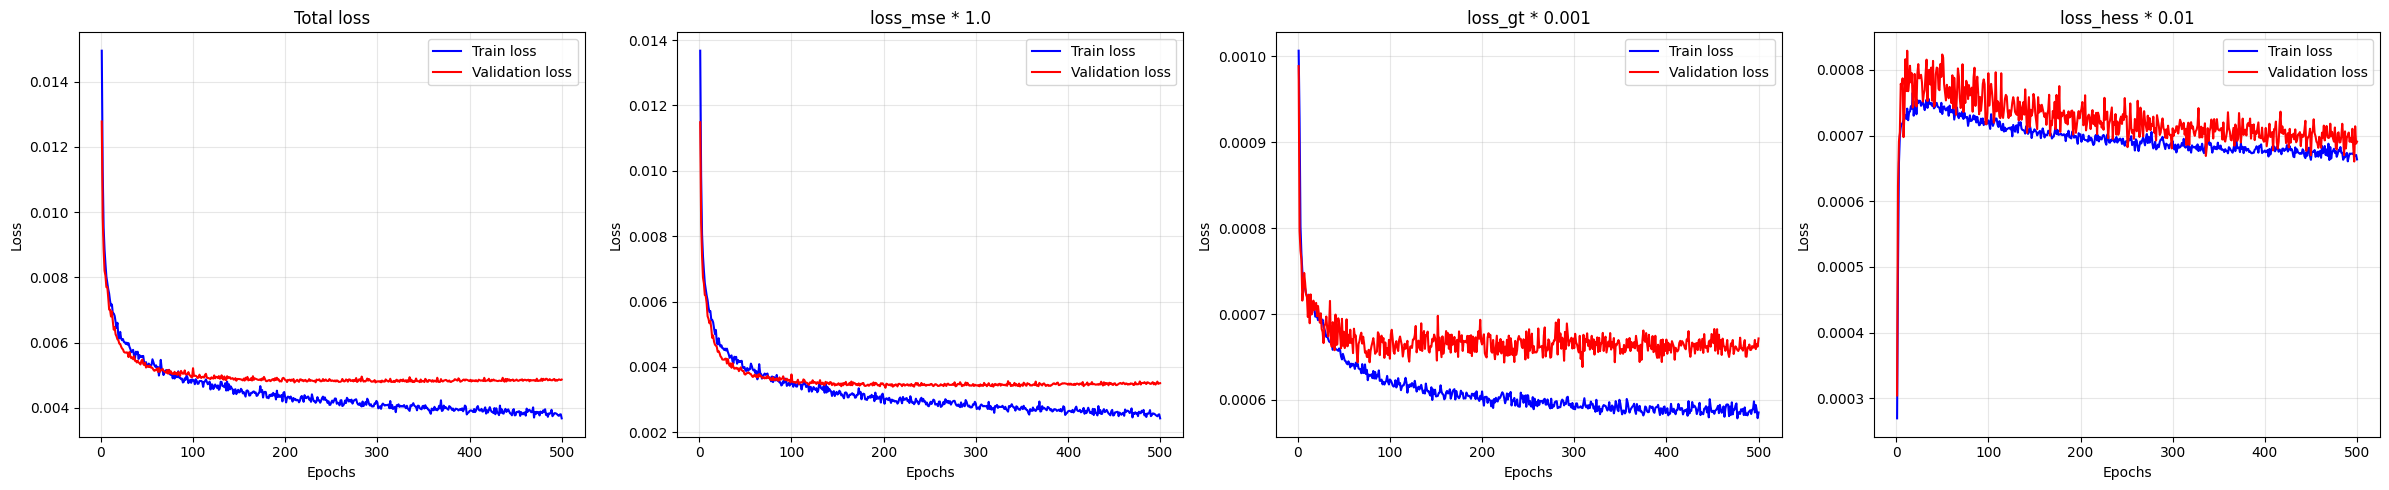

In [116]:
num_train = 1

results_folder = f'/Users/josephinelahmani/helix_mount/nn_dis/results/two_part_train_{num_train}'

with open(
    f"/Users/josephinelahmani/Desktop/nn_dis/configs/train_configs/train_config_two_parts_{num_train}.yaml", "r"
) as f:
    config = yaml.safe_load(f)

train_params = SimpleNamespace(**config["train_config"])

plot_losses(results_folder, ['total', 'mse', 'gt', 'hess'], [1.0, train_params.gt_param, train_params.beta_param], 0)

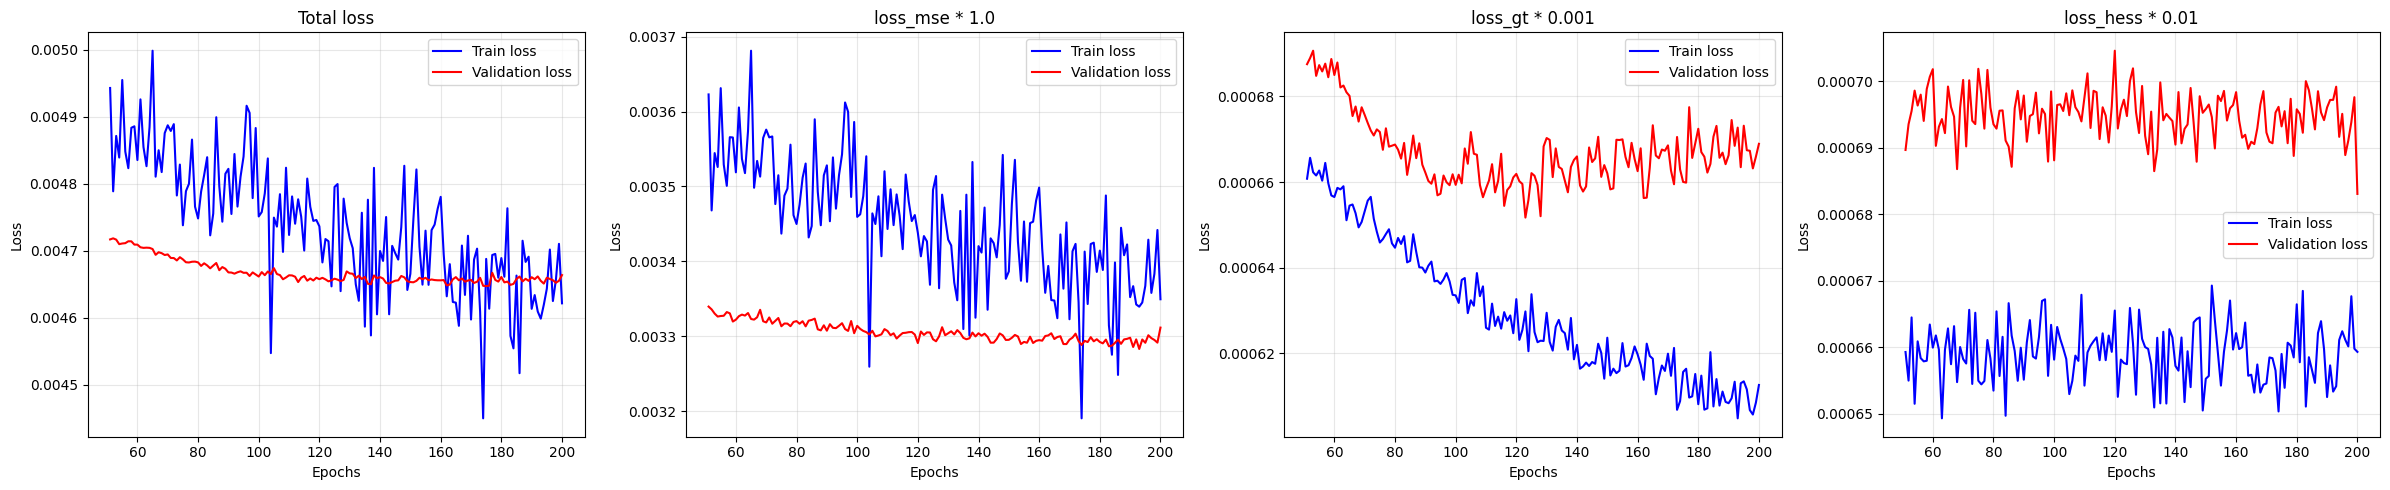

In [117]:
results_folder = f'/Users/josephinelahmani/helix_mount/nn_dis/results/two_part_train_{num_train}/finetune'

with open(
    f"/Users/josephinelahmani/Desktop/nn_dis/configs/train_configs/train_config_two_parts_{num_train}.yaml", "r"
) as f:
    config = yaml.safe_load(f)

train_params = SimpleNamespace(**config["train_config"])

plot_losses(results_folder, ['total', 'mse', 'gt', 'hess'], [1.0, train_params.gt_param, train_params.beta_param], 50)

In [124]:
crop = [(0, 2), (10,42), (300,750), (150,500)] # None
path_img_s = Path('/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif') #Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy') 
channel = 2 # None
default_spacing = None #[1.0, 0.13, 0.13]

img_s, spacing_s, dis_vxm_s, warped_vxm_s = register(img_path=path_img_s, folder_path=results_folder, model_type='aniso', nb_warps=1, channel=channel, default_spacing=default_spacing, crop=crop)
dis_vxm_s = np.transpose(dis_vxm_s, (1, 0, 2, 3, 4))
 
warped_with_of_s = warp(img_s[1], dis_vxm_s[:, 0])

save_path = Path("/Users/josephinelahmani/Desktop/nn_dis/data")

h_fista_s = np.load(save_path / "flow_fista_img_sudheer.npy")
h_hs_s = np.load(save_path / "flow_hs_img_sudheer.npy")
h_fista_s_masked = np.load(save_path / "flow_fista_img_sudheer.npy")
h_hs_s_masked = np.load(save_path / "flow_hs_img_sudheer.npy")

warped_fista_s = warp(img_s[1], h_fista_s[:, 0])
warped_hs_s = warp(img_s[1], h_hs_s[:, 0])

Attempted file (/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif) load with reader: <class 'bioio_ome_tiff.reader.Reader'> failed with error: bioio-ome-tiff does not support the image: '/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif'. Failed to parse XML for the provided file. Error: not well-formed (invalid token): line 1, column 6


In [114]:
viewer = napari.Viewer()
viewer.add_image(img_s[0], scale=spacing_s, name="I1")
viewer.add_image(img_s[1], scale=spacing_s, name="I2")
viewer.add_image(warped_vxm_s, scale=spacing_s, name="warped I2")
viewer.add_image(warped_with_of_s, scale=spacing_s, name="warped I2")
viewer.add_image(warped_fista_s, scale=spacing_s, name="warped I2 fista")
viewer.add_image(warped_hs_s, scale=spacing_s, name="warped I2 hs")
napari.run()

In [123]:
diff_im = img_s[1] - img_s[0]
diff_w = warped_vxm_s - img_s[0]
diff_w_of = warped_with_of_s - img_s[0]
diff_w_fista = warped_fista_s - img_s[0]
diff_w_hs = warped_hs_s - img_s[0]

def rmse_(diff):
    return np.sqrt(np.mean(diff**2))

print('Norms')
print('I2 - I1:', np.linalg.norm(diff_im))
print('warped - I1:', np.linalg.norm(diff_w))
print('warped with of - I1:', np.linalg.norm(diff_w_of))
print('warped_fista - I1:', np.linalg.norm(diff_w_fista))
print('warped_hs - I1:', np.linalg.norm(diff_w_hs))

print('RMSE')
print('I2 - I1:', rmse_(diff_im))
print('warped - I1:', rmse_(diff_w))
print('warped with of - I1:', rmse_(diff_w_of))
print('warped_fista - I1:', rmse_(diff_w_fista))
print('warped_hs - I1:', rmse_(diff_w_hs))

Norms
I2 - I1: 31.652721
warped - I1: 10.915361
warped with of - I1: 10.913568
warped_fista - I1: 8.773803
warped_hs - I1: 8.986853
RMSE
I2 - I1: 0.0437146
warped - I1: 0.015074865
warped with of - I1: 0.0150723895
warped_fista - I1: 0.012117223
warped_hs - I1: 0.012411459


In [125]:
get_viewer_flows(img, flows=[dis_vxm_s, h_fista_s, h_hs_s], flows_name=["VXM", "FISTA", "HS"], spacing=spacing_s, axes=[0, 1, 2])

In [127]:
save_path = Path("/Users/josephinelahmani/Desktop/nn_dis/data")

name_img = 'E_1000_nu_0.4_nb_zones_1_test_z_img.npy'

path_img_synth = Path('/Users/josephinelahmani/Desktop/nn_dis/data/E_1000_nu_0.4_nb_zones_1_test_z_img.npy')
path_ugt = Path('/Users/josephinelahmani/Desktop/nn_dis/data/E_1000_nu_0.4_nb_zones_1_test_z_ugt.npy')

img_synth, spacing_synth, dis_vxm_synth, warped_vxm_synth = register(img_path=path_img_synth, folder_path=results_folder, model_type='aniso', nb_warps=1, default_spacing=[1.0, 0.13, 0.13])
dis_vxm_synth = np.transpose(dis_vxm_synth, (1, 0, 2, 3, 4))

mask_synth = img_synth[0] > 0.1
dis_vxm_masked_synth = np.stack(
        [dis_vxm_synth[i] * mask_synth for i in range(dis_vxm_synth.shape[0])]
    )

warped_vxm_of_synth = warp(img_synth[1], dis_vxm_synth[:,0])

h_fista_synth = np.load(save_path / f"flow_fista_{name_img}")
h_fista_masked_synth = np.load(save_path / f"flow_fista_masked_{name_img}")
h_hs_synth = np.load(save_path / f"flow_hs_{name_img}")
h_hs_masked_synth = np.load(save_path / f"flow_hs_masked_{name_img}")

warped_fista_synth = warp(img_synth[1], h_fista_synth[:, 0])
warped_hs_synth = warp(img_synth[1], h_hs_synth[:, 0])

ugt_raw = np.load(path_ugt)

ugt_pixels = np.stack(
        [ugt_raw[i] / spacing_synth[i] for i in range(ugt_raw.shape[0])]
    )

ugt = np.stack(
    [
        reshape_img(ugt_pixels[0, 0]),
        reshape_img(ugt_pixels[1, 0]),
        reshape_img(ugt_pixels[2, 0]),
    ]
)

In [128]:
viewer = napari.Viewer()
viewer.add_image(img_synth[0], scale=spacing_synth, name="I1", interpolation3d="nearest")
viewer.add_image(img_synth[1], scale=spacing_synth, name="I2", interpolation3d="nearest")
viewer.add_image(warped_vxm_synth, scale=spacing_synth, name="warped I2", interpolation3d="nearest")
viewer.add_image(warped_vxm_of_synth, scale=spacing_synth, name="warped I2 OF", interpolation3d="nearest")
viewer.add_image(warped_fista_synth, scale=spacing_synth, name="warped_fista I2", interpolation3d="nearest")
viewer.add_image(warped_hs_synth, scale=spacing_synth, name="warped_hs I2", interpolation3d="nearest")
napari.run()

In [ ]:
get_viewer_flows(img_synth, flows=[ugt[:, np.newaxis], dis_vxm_masked_synth], flows_name=["UGT", "VXM"], spacing=spacing_synth, axes=[0, 1, 2])

In [ ]:
diff_im_synth = img_synth[1] - img_synth[0]
diff_w_synth = warped_vxm_synth - img_synth[0]
diff_w_of_synth = warped_vxm_of_synth - img_synth[0]
diff_w_hs_synth = warped_hs_synth - img_synth[0]
diff_w_fista_synth = warped_fista_synth - img_synth[0]

diff_u_vxm = dis_vxm_masked_synth - ugt[:, np.newaxis]
diff_u_hs = h_hs_masked_synth - ugt[:, np.newaxis]
diff_u_fista = h_fista_masked_synth - ugt[:, np.newaxis]

def rmse_(diff):
    return np.sqrt(np.mean(diff**2))

print('Warping')
print('Norms')
print('I2 - I1:', np.linalg.norm(diff_im_synth))
print('warped - I1:', np.linalg.norm(diff_w_synth))
print('warped_with_of - I1:', np.linalg.norm(diff_w_of_synth))
print('warped_hs - I1:', np.linalg.norm(diff_w_hs_synth))
print('warped_fista - I1:', np.linalg.norm(diff_w_fista_synth))

print('\nRMSE')
print('I2 - I1:', rmse_(diff_im))
print('warped - I1:', rmse_(diff_w_synth))
print('warped_with_of - I1:', rmse_(diff_w_of_synth))
print('warped_hs - I1:', rmse_(diff_w_hs_synth))
print('warped_fista - I1:', rmse_(diff_w_fista_synth))



print('\nFlows')
print('Norms')
print('dis_vxm - ugt:', np.linalg.norm(diff_u_vxm))
print('dis_hs - ugt:', np.linalg.norm(diff_u_hs))
print('dis_fista - ugt:', np.linalg.norm(diff_u_fista))

print('\nRMSE')
print("dis_vxm - ugt", rmse_(diff_u_vxm))
print("dis_hs - ugt", rmse_(diff_u_hs))
print("dis_fista - ugt", rmse_(diff_u_fista))

Norms
I2 - I1: 9.496513
warped - I1: 10.99181
warped_with_of - I1: 10.991812
warped_hs - I1: 5.521374
warped_fista - I1: 6.6211815

RMSE
I2 - I1: 0.0437146
warped - I1: 0.015180436
warped_with_of - I1: 0.015180439
warped_hs - I1: 0.0076253926
warped_fista - I1: 0.0091443015


In [74]:
path_img = Path('/Users/josephinelahmani/helix_mount/data/fractals/perlin/test/fractal_44_12_funcs_img.npy')
path_ugt = Path('/Users/josephinelahmani/helix_mount/data/fractals/perlin/all_data/fractal_44_12_funcs_ugt.npy')
#results_folder = '/Users/josephinelahmani/helix_mount/nn_dis/results/train_2'

img, spacing, dis_vxm, warped_vxm = register(img_path=path_img, folder_path=results_folder, model_type='aniso', nb_warps=1, default_spacing=[4.0, 1.0, 1.0])
dis_vxm = np.transpose(dis_vxm, (1, 0, 2, 3, 4))
ugt = np.load(path_ugt)
u_gt = np.stack(
    [
        reshape_img(ugt[0]),
        reshape_img(ugt[1]),
        reshape_img(ugt[2]),
    ]
)

image_loss_fn = network.losses.MSE()
grad_loss_fn = network.losses.SpatialGradient("l2")
hessian_loss_fn = network.losses.SpatialHessian("l2")
gt_loss_fn = network.losses.GT_comp()

img_loss_zero = image_loss_fn(torch.from_numpy(img[0]), torch.from_numpy(img[1]), torch.from_numpy(np.ones_like(img[0])))
img_loss_gt = image_loss_fn(torch.from_numpy(img[0]), warp(torch.from_numpy(img[1]), u_gt), torch.from_numpy(np.ones_like(img[0])))
img_loss_pred = image_loss_fn(torch.from_numpy(img[0]), warp(torch.from_numpy(img[1]), dis_vxm[:, 0]), torch.from_numpy(np.ones_like(img[0])))

print("loss zero displacement", img_loss_zero)
print("loss gt displacement", img_loss_gt)
print("loss vxm displacement", img_loss_pred)

loss zero displacement tensor(0.0003)
loss gt displacement tensor(8.3400e-06)
loss vxm displacement tensor(0.0002)


In [124]:
mask = img > 0.05

viewer_mask = napari.Viewer()
viewer_mask.add_image(mask, scale=(4.0, 1.0, 1.0))
napari.run()

In [5]:
# viewer = napari.Viewer()
# viewer.add_image(img_padded, scale=new_spacing)

Min: -5.7958
Max: 3.8522
Mean abs: 0.7774


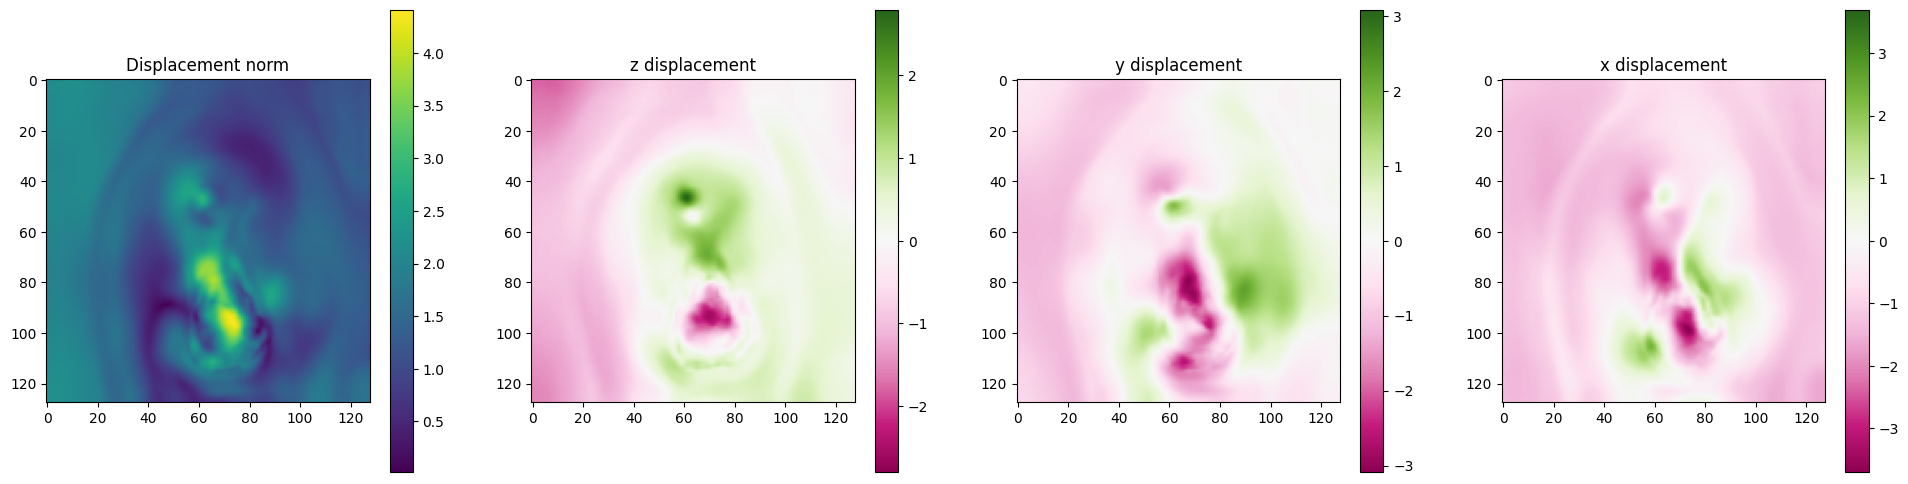

In [14]:
### Visualize displacement results

print(f"Min: {dis.min():.4f}")
print(f"Max: {dis.max():.4f}")
print(f"Mean abs: {np.abs(dis).mean():.4f}")

dis_z_max = np.max(np.abs(dis[0, 0, z_stack]))
dis_y_max = np.max(np.abs(dis[0, 1, z_stack]))
dis_x_max = np.max(np.abs(dis[0, 2, z_stack]))

fig, axes = plt.subplots(1, 4, figsize=(24, 6))

im0 = axes[0].imshow(np.linalg.norm(dis[0, :, z_stack], axis=0))
fig.colorbar(im0, ax = axes[0])
axes[0].set_title('Displacement norm')
im1 = axes[1].imshow(dis[0, 0, z_stack], cmap = 'PiYG', vmin = -dis_z_max, vmax = dis_z_max)
fig.colorbar(im1, ax = axes[1])
axes[1].set_title('z displacement')
im2 = axes[2].imshow(dis[0, 1, z_stack], cmap = 'PiYG', vmin = -dis_y_max, vmax = dis_y_max)
fig.colorbar(im2, ax = axes[2])
axes[2].set_title('y displacement')
im3 = axes[3].imshow(dis[0, 2, z_stack], cmap = 'PiYG', vmin = -dis_x_max, vmax = dis_x_max)
fig.colorbar(im3, ax = axes[3])
axes[3].set_title('x displacement')
plt.show()

# Model comparisons

In [8]:
def rmse_(diff):
    return float(np.sqrt(np.mean(diff ** 2)))

def save_flow_vxm(folder_img: Path, results_folder: Path, name:str, save_path:Path = None, channel:int = None, crop: Tuple[Tuple[int, int], Tuple[int, int], Tuple[int, int]] = None, default_spacing: Tuple[float]=None):
    save_path.mkdir(exist_ok=True)
    
    metrics_rows = []

    for path_img in folder_img.iterdir():
        ext = os.path.splitext(path_img)[1].lower()
        if ext in [".npy", ".tiff", ".tif"]:
            img_padded, spacing, dis, warped_im = register(img_path=path_img, folder_path=results_folder, channel=channel, crop=crop, default_spacing=default_spacing)
            
            dis_vxm = dis.transpose(1, 0, 2, 3, 4)
            mask_padded = img_padded[0] > 0.1
            dis_vxm_final = np.stack([dis_vxm[i] * mask_padded * spacing[i] for i in range(dis.shape[1])])
            
            diff_im = img_padded[1] - img_padded[0]
            diff_warped = warped_im - img_padded[0]

            norm_I2_I1 = np.linalg.norm(diff_im)
            norm_warped_I1 = np.linalg.norm(diff_warped)

            rmse_I2_I1 = rmse_(diff_im)
            rmse_warped_I1 = rmse_(diff_warped)
            
            metrics_rows.append({
                        "model": name,
                        "image": path_img.name,
                        "norm_I2_minus_I1": float(norm_I2_I1),
                        "rmse_I2_minus_I1": float(rmse_I2_I1),
                        "norm_warped_minus_I1": float(norm_warped_I1),
                        "rmse_warped_minus_I1": float(rmse_warped_I1),
                    })

            if save_path is not None :
                np.save(save_path / f"flow_vxm_{path_img.name}_{name}", dis_vxm_final)
                np.save(save_path / f"warped_im_vxm_{path_img.name}_{name}", warped_im)
                np.save(save_path / f"init_im_{path_img.name}_{name}", img_padded)
            
        mean_row = {
            "model": name,
            "image": "MEAN",
            "norm_I2_minus_I1": float(np.mean([
                row["norm_I2_minus_I1"] for row in metrics_rows
            ])),
            "rmse_I2_minus_I1": float(np.mean([
                row["rmse_I2_minus_I1"] for row in metrics_rows
            ])),
            "norm_warped_minus_I1": float(np.mean([
                row["norm_warped_minus_I1"] for row in metrics_rows
            ])),
            "rmse_warped_I1": float(np.mean([
                row["rmse_warped_minus_I1"] for row in metrics_rows
            ])),
        }
    
    mean_row["rmse_warped_minus_I1"] = mean_row.pop("rmse_warped_I1")
    metrics_rows.append(mean_row)

    csv_path = results_folder / f"metrics_vxm_{name}.csv"

    fieldnames = [
        "model",
        "image",
        "norm_I2_minus_I1",
        "rmse_I2_minus_I1",
        "norm_warped_minus_I1",
        "rmse_warped_minus_I1",
    ]

    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(metrics_rows)
        
    return metrics_rows
            

models_to_compare = {
    # 'train_1': 'a_0.2_b_0.01',
    # 'train_2': 'a_0.3_b_0.1',
    # 'train_3': 'a_0.25_b_0.05',
    # 'train_5': 'a_b_0.2', 
    # 'train_6_': 'a_b_0.1',
    # 'train_7': 'a_0.2_b_0', 
    # 'train_8': 'a_0.1_b_0', 
    'train_9': 'a_0.1_b_0 both types',
    'train_10': 'a_b_0.1 both types',
    'train_11': 'a_0.1_b_0.01 both types',
}

channel = None
crop = None
default_spacing = [1.0, 0.13, 0.13]
base_img_folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
base_results_folder = Path('/Users/josephinelahmani/helix_mount/nn_dis/results')
save_path = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_vxm')

for model_folder, name in models_to_compare.items():
    results_folder = base_results_folder / model_folder
    save_flow_vxm(base_img_folder, results_folder, name, save_path, channel, crop, default_spacing)

In [52]:
for model_folder, name in models_to_compare.items():
    csv_path = f'{base_results_folder}/{model_folder}/metrics_vxm_{name}.csv'
    with open(csv_path, newline="") as f:
        reader = csv.DictReader(f)
        for row in reader:
            if row["image"] == "MEAN":
                norm_warped = float(row["norm_warped_minus_I1"])
                rmse_warped = float(row["rmse_warped_minus_I1"])

                print(
                    f"{name:20s} | "
                    f"Norm warped - I1: {norm_warped:.6f} | "
                    f"RMSE warped - I1: {rmse_warped:.6f}"
                )
                break

a_0.1_b_0 both types | Norm warped - I1: 8.278997 | RMSE warped - I1: 0.011434
a_b_0.1 both types   | Norm warped - I1: 8.830185 | RMSE warped - I1: 0.012195
a_0.1_b_0.01 both types | Norm warped - I1: 8.336033 | RMSE warped - I1: 0.011513


# Method comparison

## Synthetic images

In [23]:
path_img = Path("/Users/josephinelahmani/Desktop/nn_dis/tests/E_1000_nu_0.4_nb_zones_1_test_z_img.npy")

In [6]:
def warp_vxm_versop(moving, displacement, mode: str = "bilinear"):
    if not torch.is_tensor(moving):
        moving = torch.as_tensor(moving, dtype=torch.float32)
    if moving.ndim == 3:      # D,H,W
        moving = moving.unsqueeze(0).unsqueeze(0)
    elif moving.ndim == 4:    # C,D,H,W
        moving = moving.unsqueeze(0)

    if not torch.is_tensor(displacement):
        displacement = torch.as_tensor(displacement, dtype=moving.dtype, device=moving.device)
    else:
        displacement = displacement.to(dtype=moving.dtype, device=moving.device)

    if displacement.ndim == 4:   # 3,D,H,W
        displacement = displacement.unsqueeze(0)
        
    shape = moving.shape[2:]
    ndim = len(shape)

    axes = [
        torch.arange(0, s, dtype=displacement.dtype, device=displacement.device)
        for s in shape
    ]

    meshgrid = torch.stack(torch.meshgrid(*axes, indexing="ij"), dim=0).contiguous()

    new_locs = meshgrid + displacement

    sizes = torch.tensor(
        shape, dtype=displacement.dtype, device=displacement.device
    )

    scales = 2.0 / (sizes - 1).clamp(min=1)
    broadcast_shape = (ndim,) + (1,) * len(shape)
    scales = scales.view(broadcast_shape)

    grid = new_locs * scales - 1.0

    grid = grid.flip(
        dims=(1,)
    )  # Convert from ij (z,y,x) to (x,y,z) convention for grid_sample
    grid = grid.permute(0, 2, 3, 4, 1)  # To have a (N, D, H, W, C) shape

    return torch.nn.functional.grid_sample(
        moving, grid, mode=mode, padding_mode="reflection", align_corners=True
    )

In [8]:
viewer = napari.Viewer()
viewer.add_image(img, scale=[1.0, 0.13, 0.13])

<Image layer 'img' at 0x31ffb0380>

In [24]:
def add_flows_viewer(flow, flow_name, ax, viewer, spacing):
    img = viewer.add_image(
        flow[ax, 0],
        name=f"{flow_name}, ax={ax}",
        scale=spacing,
        colormap="cividis",
        interpolation3d="nearest",
    )
    img.colorbar.visible = True


def get_viewer(img, flows, flows_name, spacing, axes):
    viewer = napari.Viewer()
    viewer.add_image(
        img,
        scale=spacing,
        interpolation3d="nearest",
    )

    for i, flow in enumerate(flows):
        for ax in axes:
            add_flows_viewer(flow, flows_name[i], ax, viewer, spacing)

    napari.run()

In [ ]:
img, spacing, dis_vxm, warped_vxm = register(img_path=path_img, folder_path=results_folder, model_type='aniso', nb_warps=1, default_spacing=[1.0, 0.13, 0.13])
dis_vxm = np.transpose(dis_vxm, (1, 0, 2, 3, 4))
mask = img[0] != 0
dis_vxm_final = np.stack(
        [dis_vxm[i] * mask / spacing[i] for i in range(dis_vxm.shape[0])]
    )

In [26]:
get_viewer(img, [dis_vxm, dis_vxm_final], ["VXM", "VXM masked"], spacing, axes=[0])

In [ ]:
from optical_flow.algorithms import warp

# warped_gt = warp_vxm_versop(img[1], u_gt)
# warped_vxm_ = warp_vxm_versop(img[1], dis_vxm)

warped_gt = warp(img[1], u_gt)
#warped_vxm_ = warp(img[1], dis_vxm[:,0])
#warped_fista = warp(img[1], h_fista[:,0], spacing=spacing)
warped_hs = warp(img[1], h_hs[:, 0])

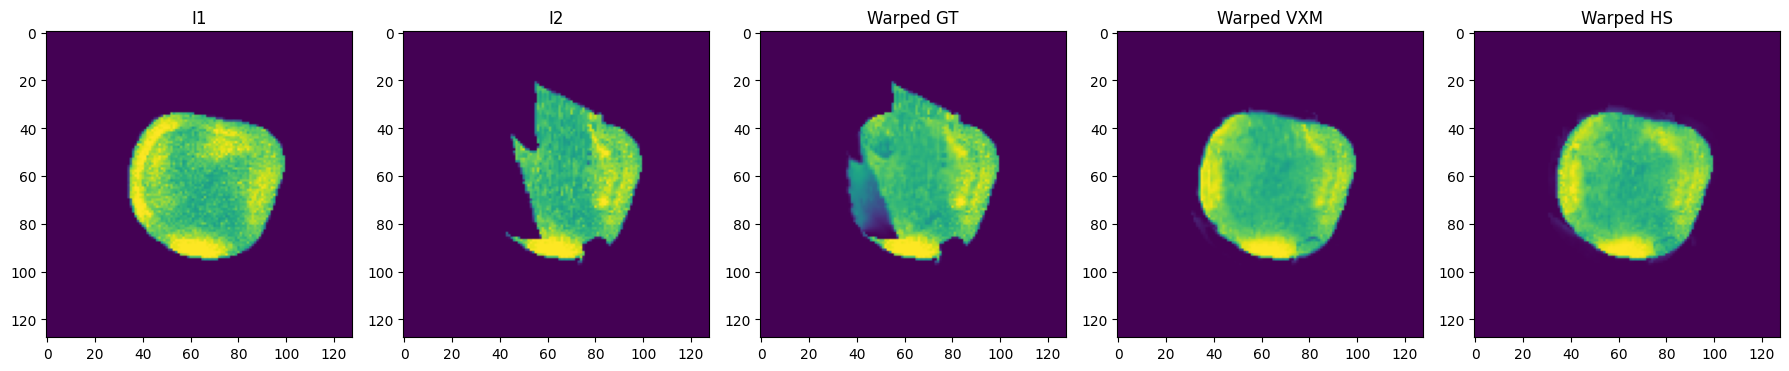

In [11]:
z = 12

fig, axes = plt.subplots(1, 5, figsize=(18, 10))

axes[0].imshow(img[0, z])
axes[0].set_title("I1")
axes[1].imshow(img[1, z])
axes[1].set_title("I2")
axes[2].imshow(warped_gt[z])
axes[2].set_title("Warped GT")
# axes[3].imshow(warped_fista[z])
# axes[3].set_title("Warped FISTA")
axes[3].imshow(warped_vxm[z])
axes[3].set_title("Warped VXM")
axes[4].imshow(warped_hs[z])
axes[4].set_title("Warped HS")

plt.tight_layout()
plt.show()

NameError: name 'h_fista_final' is not defined

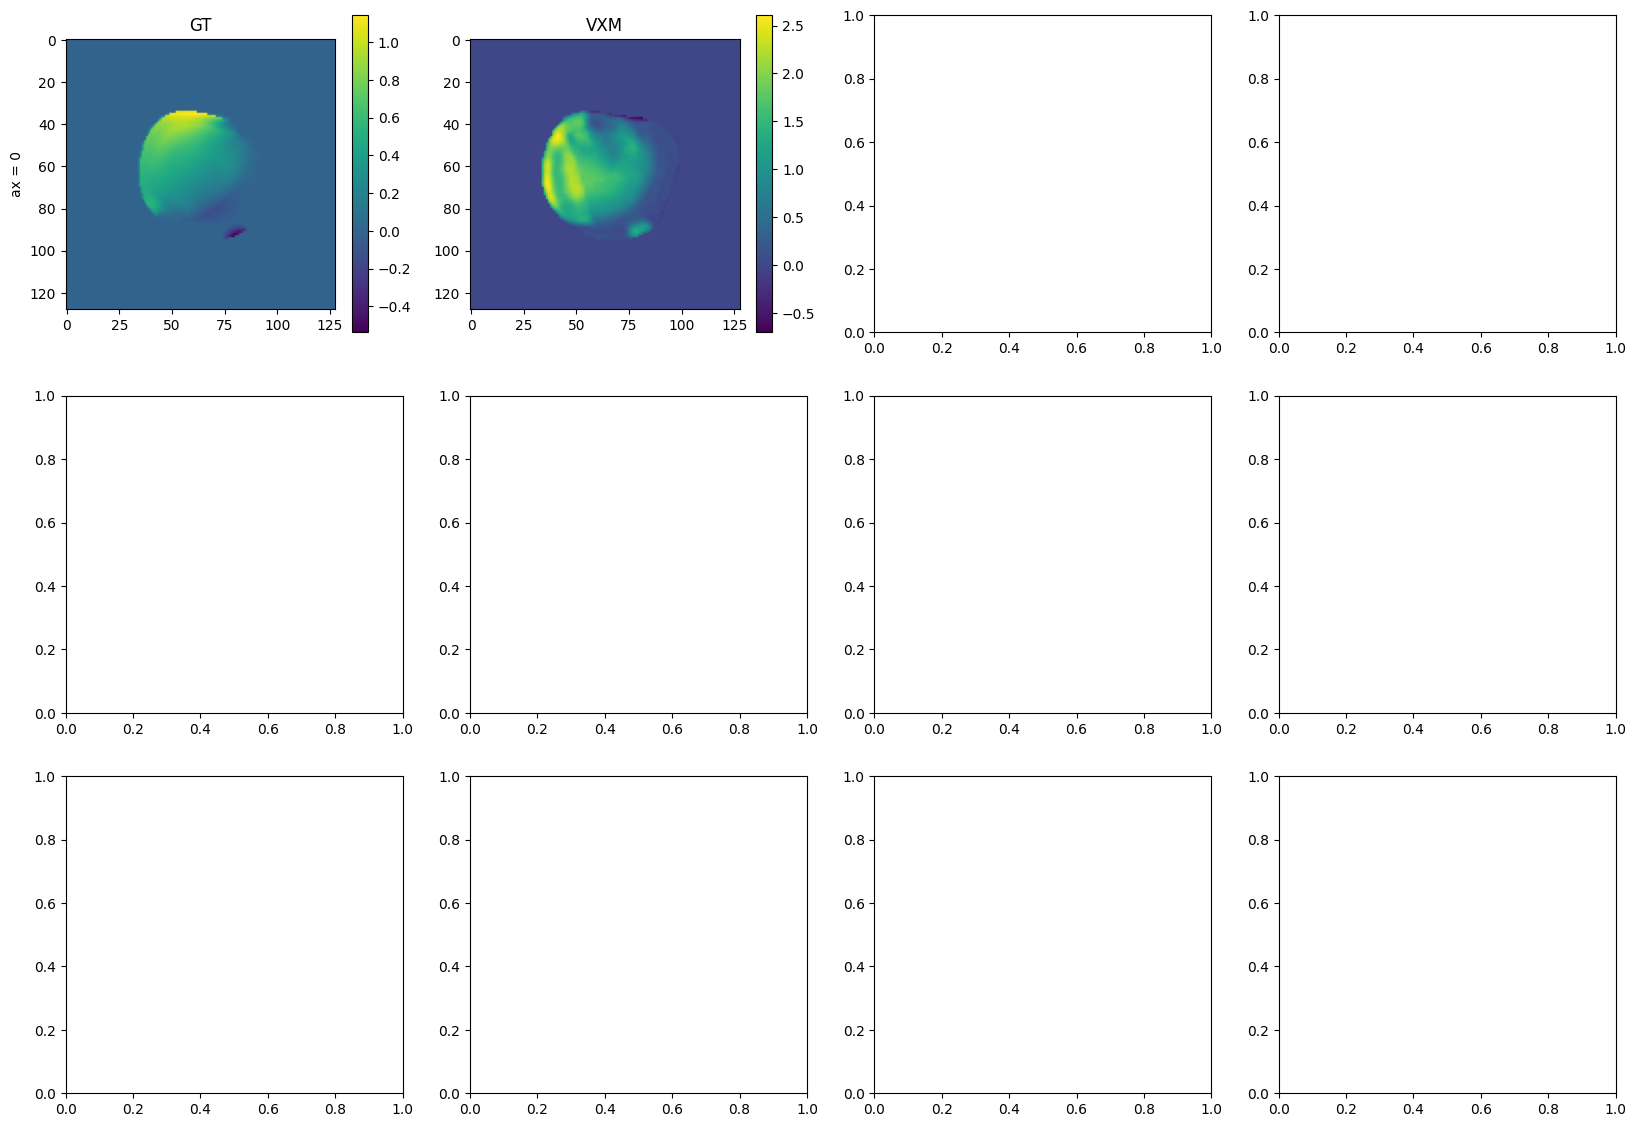

In [12]:
z = 12

fig, axes = plt.subplots(3, 4, figsize=(20, 14))

im00 = axes[0, 0].imshow(u_gt[0, z])
fig.colorbar(im00, ax=axes[0, 0])
axes[0, 0].set_title("GT")
axes[0, 0].set_ylabel("ax = 0")
im01 = axes[0, 1].imshow(dis_vxm_final[0, 0, z])
fig.colorbar(im01, ax=axes[0, 1])
axes[0, 1].set_title("VXM")
im02 = axes[0, 2].imshow(h_fista_final[0, 0, z])
fig.colorbar(im02, ax=axes[0, 2])
axes[0, 2].set_title("FISTA")
im03 = axes[0, 3].imshow(h_hs_final[0, 0, z])
fig.colorbar(im03, ax=axes[0, 3])
axes[0, 3].set_title("HS")

im10 = axes[1, 0].imshow(u_gt[1, z])
fig.colorbar(im10, ax=axes[1, 0])
axes[1, 0].set_ylabel("ax = 1")
im11 = axes[1, 1].imshow(dis_vxm_final[1, 0, z])
fig.colorbar(im11, ax=axes[1, 1])
im12 = axes[1, 2].imshow(h_fista_final[1, 0, z])
fig.colorbar(im12, ax=axes[1, 2])
im13 = axes[1, 3].imshow(h_hs_final[1, 0, z])
fig.colorbar(im13, ax=axes[1, 3])

im20 = axes[2, 0].imshow(u_gt[2, z])
fig.colorbar(im20, ax=axes[2, 0])
axes[2, 0].set_ylabel("ax = 2")
im21 = axes[2, 1].imshow(dis_vxm_final[2, 0, z])
fig.colorbar(im21, ax=axes[2, 1])
im22 = axes[2, 2].imshow(h_fista_final[2, 0, z])
fig.colorbar(im22, ax=axes[2, 2])
im23 = axes[2, 3].imshow(h_hs_final[2, 0, z])
fig.colorbar(im23, ax=axes[2, 3])

plt.tight_layout()
plt.show()

In [49]:
path_results_of = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_flows')

for algo in ['fista', 'hs', 'tvl1']: 
    csv_path = f'{path_results_of}/metrics_{algo}.csv'
    with open(csv_path, newline="") as f:
        reader = csv.DictReader(f)
        for row in reader:
            if row["image"] == "MEAN":
                norm_warped = float(row["norm_warped_minus_I1"])
                rmse_warped = float(row["rmse_warped_minus_I1"])

                print(
                    f"{algo:20s} | "
                    f"Norm warped - I1: {norm_warped:.6f} | "
                    f"RMSE warped - I1: {rmse_warped:.6f}"
                )
                break

fista                | Norm warped - I1: 17.720869 | RMSE warped - I1: 0.024474
hs                   | Norm warped - I1: 15.030830 | RMSE warped - I1: 0.020759
tvl1                 | Norm warped - I1: 28.607501 | RMSE warped - I1: 0.039509


In [50]:
def get_new_spacing(
    original_shape,
    old_spacing=(1.0, 0.13, 0.13),
    target_d=32,
    target_h=128,
    target_w=128,
):
    old_d, old_h, old_w = original_shape
    spacing_d, spacing_h, spacing_w = old_spacing

    # D is padded in reshape_img, not resampled
    new_spacing_d = spacing_d

    # H/W are resampled
    new_spacing_h = spacing_h * old_h / target_h
    new_spacing_w = spacing_w * old_w / target_w

    return (new_spacing_d, new_spacing_h, new_spacing_w)

In [27]:
folder_img = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
ugt_base_folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/all_data')
path_results_of = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_flows')
path_results_vxm = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_vxm')

rmse_vxm, rmse_fista, rmse_hs, rmse_tvl1 = [], [], [], []

for path_img in folder_img.iterdir():
    name_img = path_img.name
    ugt_name = name_img.replace('_img.npy', '_ugt.npy')
    ugt_path = ugt_base_folder / ugt_name
    ugt_init = np.load(ugt_path)
    u_gt = np.stack([reshape_img(ugt_init[0, 0]), reshape_img(ugt_init[2, 0]), reshape_img(ugt_init[1, 0])])
         
    dis_vxm, warped_vxm = np.load(f'{path_results_vxm}/flow_vxm_{name_img}_a_0.1_b_0 both types.npy'), np.load(f'{path_results_vxm}/warped_im_vxm_{name_img}_a_0.1_B_0 both types.npy')
    dis_fista, warped_fista = np.load(f'{path_results_of}/flow_fista_{name_img}'), np.load(f'{path_results_of}/warped_fista_{name_img}')
    dis_hs, warped_hs = np.load(f'{path_results_of}/flow_hs_{name_img}'), np.load(f'{path_results_of}/warped_hs_{name_img}')
    dis_tvl1, warped_tvl1 = np.load(f'{path_results_of}/flow_tvl1_{name_img}'), np.load(f'{path_results_of}/warped_tvl1_{name_img}')
    
    rmse_vxm.append(rmse(u_gt, dis_vxm[:,0]))
    rmse_fista.append(rmse(u_gt, dis_fista[:,0]))
    rmse_hs.append(rmse(u_gt, dis_hs[:,0]))
    rmse_tvl1.append(rmse(u_gt, dis_tvl1[:,0]))

In [28]:
print('RMSE')
print('vxm:', np.mean(rmse_vxm))
print('fista:', np.mean(rmse_fista))
print('hs:', np.mean(rmse_hs))
print('tvl1:', np.mean(rmse_tvl1))

RMSE
vxm: 0.12713799
fista: 0.15012826596177548
hs: 0.12460620598526874
tvl1: 0.12308354330875439


In [65]:
name_img = 'E_1000.0_nu_0.4_nb_zones_9_im_01_seed_05_img.npy'

ugt_name = name_img.replace('_img.npy', '_ugt.npy')
ugt_path = ugt_base_folder / ugt_name
ugt_init = np.load(ugt_path)
u_gt = np.stack([reshape_img(ugt_init[0, 0]), reshape_img(ugt_init[2, 0]), reshape_img(ugt_init[1, 0])])

folder_img = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
path_img = folder_img / name_img

img, spacing, dis_vxm, warped_vxm = register(img_path=path_img, folder_path=results_folder, model_type='aniso', nb_warps=5) #np.load(f'{path_results_vxm}/flow_vxm_{name_img}_a_0.1_b_0 both types.npy'), np.load(f'{path_results_vxm}/warped_im_vxm_{name_img}_a_0.1_B_0 both types.npy')
dis_fista, warped_fista = np.load(f'{path_results_of}/flow_fista_{name_img}'), np.load(f'{path_results_of}/warped_fista_{name_img}')
dis_hs, warped_hs = np.load(f'{path_results_of}/flow_hs_{name_img}'), np.load(f'{path_results_of}/warped_hs_{name_img}')
dis_tvl1, warped_tvl1 = np.load(f'{path_results_of}/flow_tvl1_{name_img}'), np.load(f'{path_results_of}/warped_tvl1_{name_img}')

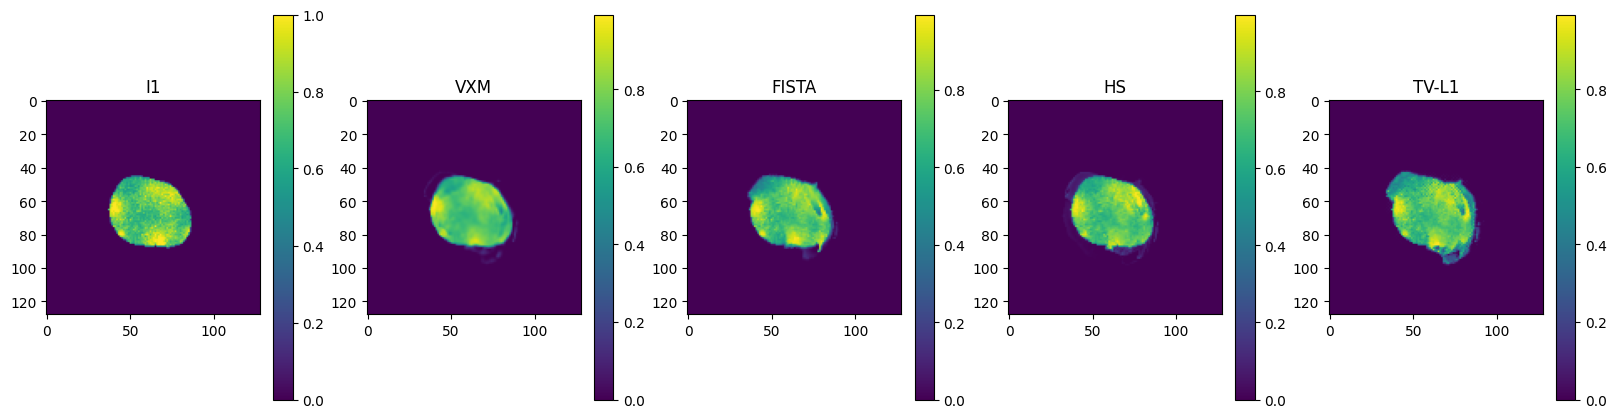

In [63]:
img_padded = np.load(f'{path_results_of}/init_im_{name_img}')

z = 19
ax = 0

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
im0 = axes[0].imshow(img_padded[0, z])
fig.colorbar(im0, ax=axes[0])
axes[0].set_title('I1')
im1 = axes[1].imshow(warped_vxm[z])
fig.colorbar(im1, ax=axes[1])
axes[1].set_title('VXM')
im2 = axes[2].imshow(warped_fista[z])
fig.colorbar(im2, ax=axes[2])
axes[2].set_title('FISTA')
im3 = axes[3].imshow(warped_hs[z])
fig.colorbar(im3, ax=axes[3])
axes[3].set_title('HS')
im4 = axes[4].imshow(warped_tvl1[z])
fig.colorbar(im4, ax=axes[4])
axes[4].set_title('TV-L1')
plt.show()

In [68]:
dis_vxm = np.transpose(dis_vxm, (1, 0, 2, 3, 4))

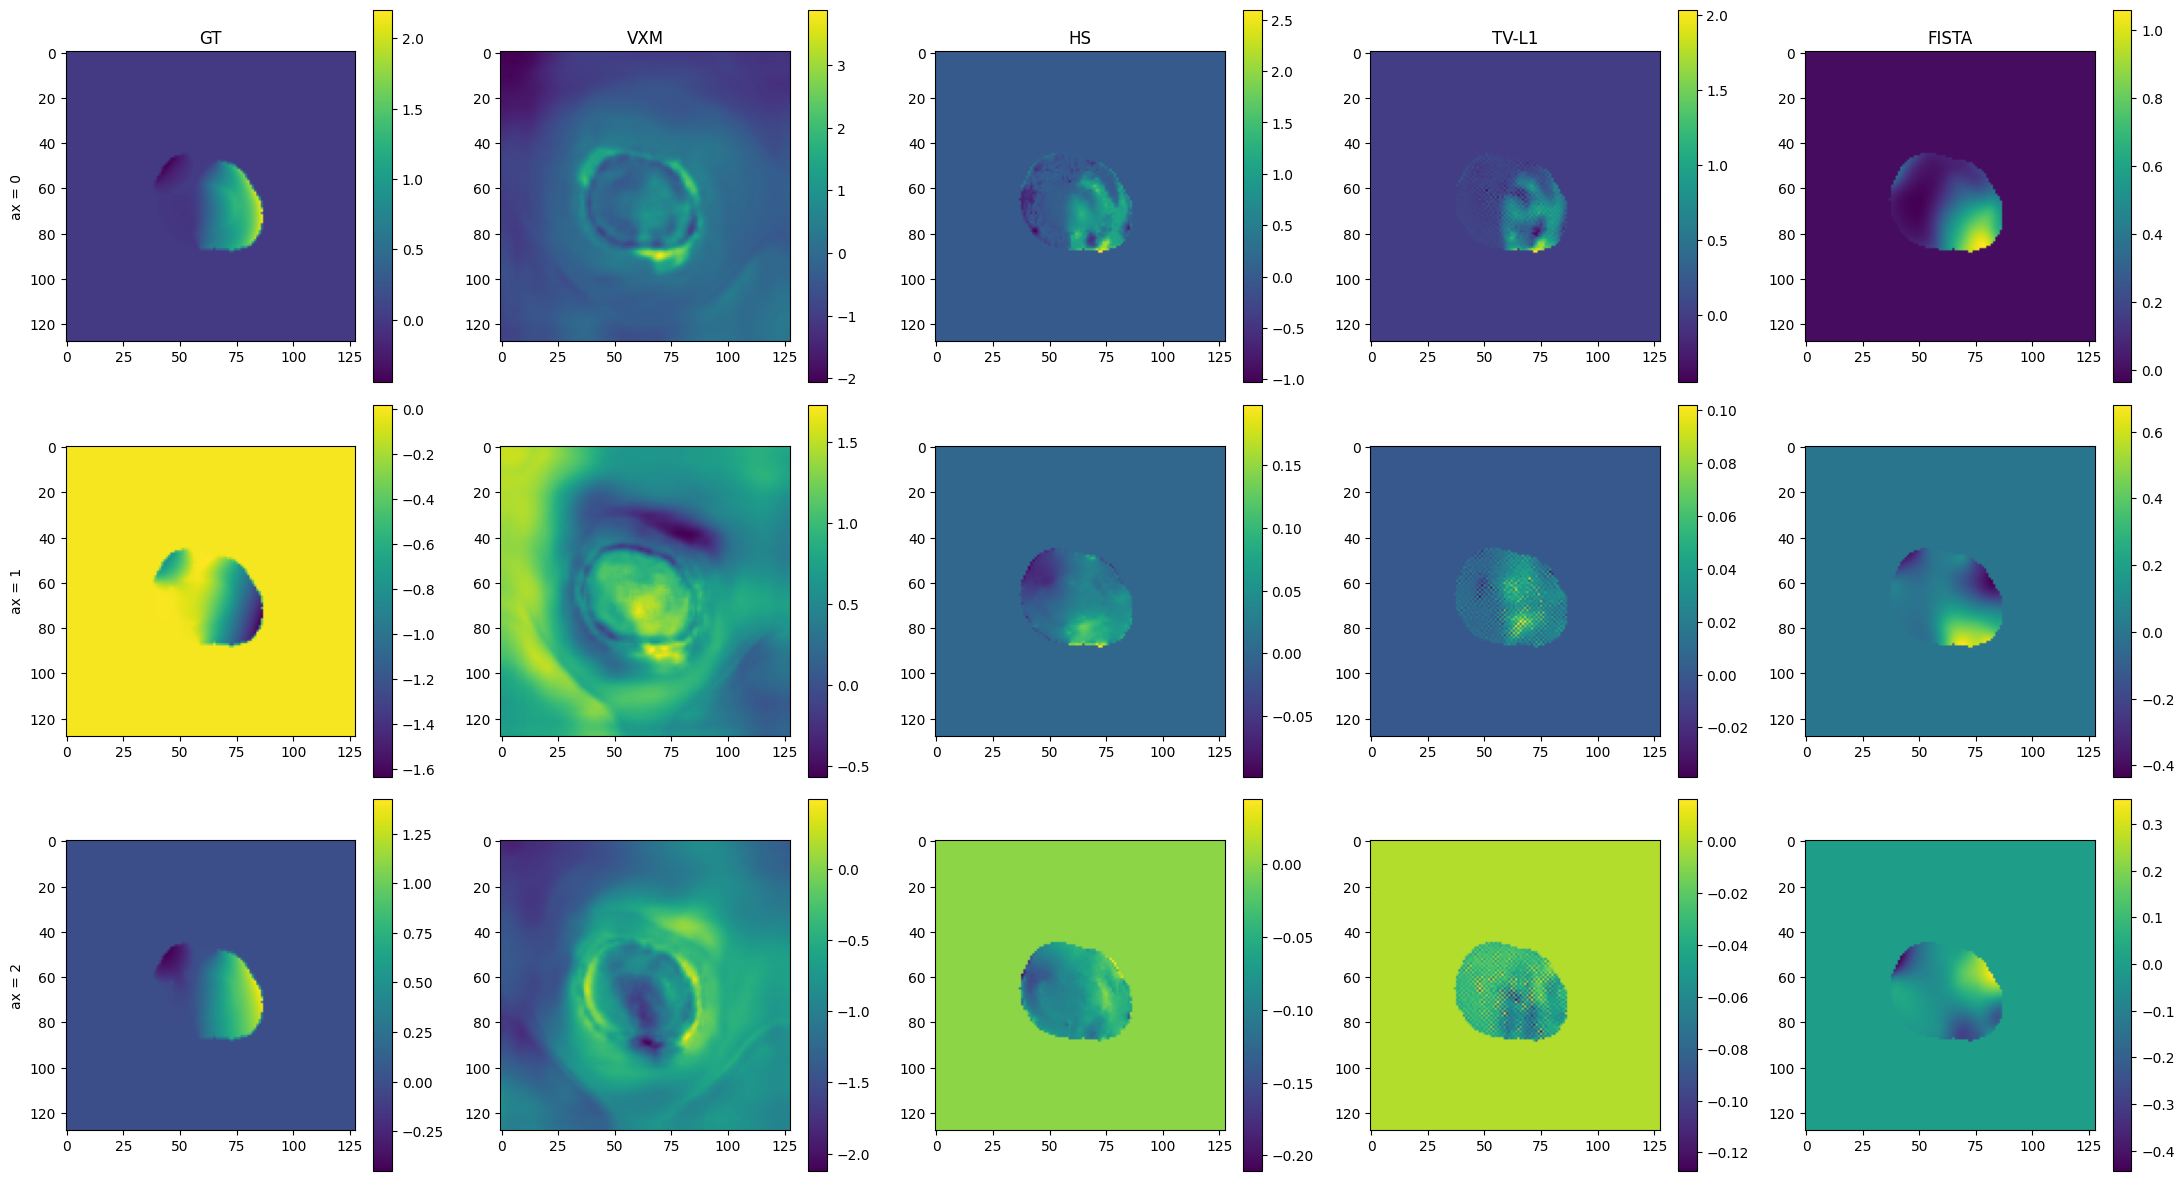

In [69]:
z = 19

fig, axes = plt.subplots(3, 5, figsize=(22, 12))

im00 = axes[0, 0].imshow(u_gt[0, z])
fig.colorbar(im00, ax=axes[0, 0])
axes[0, 0].set_title("GT")
axes[0, 0].set_ylabel("ax = 0")
im01 = axes[0, 1].imshow(dis_vxm[0, 0, z])
fig.colorbar(im01, ax=axes[0, 1])
axes[0, 1].set_title("VXM")
im02 = axes[0, 2].imshow(dis_hs[0, 0, z])
fig.colorbar(im02, ax=axes[0, 2])
axes[0, 2].set_title("HS")
im03 = axes[0, 3].imshow(dis_tvl1[0, 0, z])
fig.colorbar(im03, ax=axes[0, 3])
axes[0, 3].set_title("TV-L1")
im04 = axes[0, 4].imshow(dis_fista[0, 0, z])
fig.colorbar(im04, ax=axes[0, 4])
axes[0, 4].set_title("FISTA")

im10 = axes[1, 0].imshow(u_gt[1, z])
fig.colorbar(im10, ax=axes[1, 0])
axes[1, 0].set_ylabel("ax = 1")
im11 = axes[1, 1].imshow(dis_vxm[1, 0, z])
fig.colorbar(im11, ax=axes[1, 1])
im12 = axes[1, 2].imshow(dis_hs[1, 0, z])
fig.colorbar(im12, ax=axes[1, 2])
im13 = axes[1, 3].imshow(dis_tvl1[1, 0, z])
fig.colorbar(im13, ax=axes[1, 3])
im14 = axes[1, 4].imshow(dis_fista[1, 0, z])
fig.colorbar(im14, ax=axes[1, 4])

im20 = axes[2, 0].imshow(u_gt[2, z])
fig.colorbar(im20, ax=axes[2, 0])
axes[2, 0].set_ylabel("ax = 2")
im21 = axes[2, 1].imshow(dis_vxm[2, 0, z])
fig.colorbar(im21, ax=axes[2, 1])
im22 = axes[2, 2].imshow(dis_hs[2, 0, z])
fig.colorbar(im22, ax=axes[2, 2])
im23 = axes[2, 3].imshow(dis_tvl1[2, 0, z])
fig.colorbar(im23, ax=axes[2, 3])
im24 = axes[2, 4].imshow(dis_fista[2, 0, z])
fig.colorbar(im24, ax=axes[2, 4])

plt.tight_layout()
plt.show()

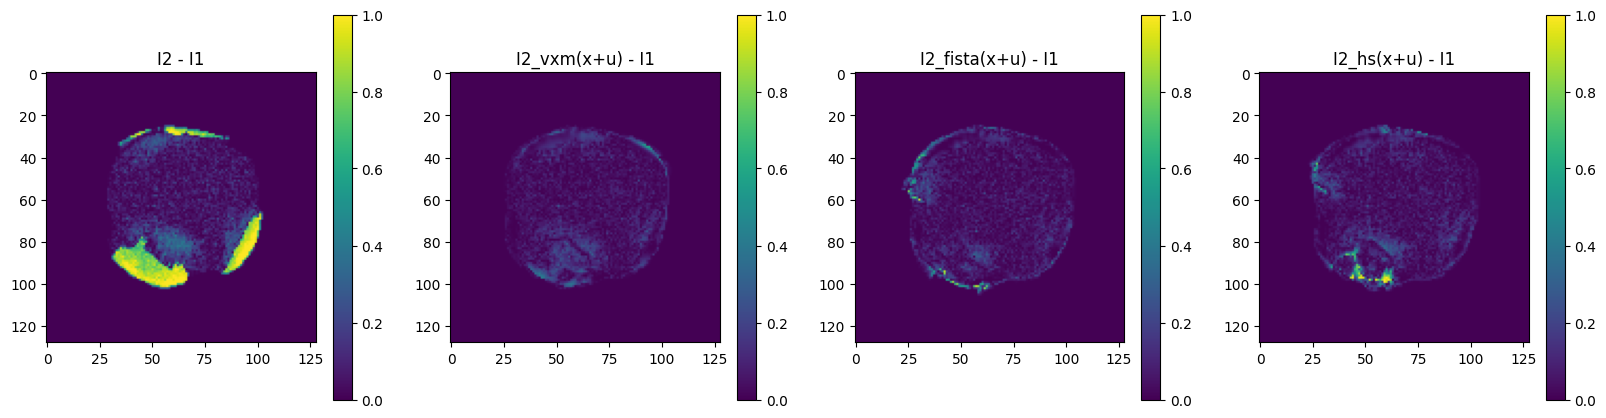

In [66]:
warped_vxm = w_synth

z_stack = 15

diff0 = np.abs(img_padded_synth[1, z_stack] - img_padded_synth[0, z_stack])
diff1 = np.abs(warped_vxm[z_stack] - img_padded_synth[0, z_stack])
diff2 = np.abs(warped_fista[z_stack] - img_padded_synth[0, z_stack])
diff3 = np.abs(warped_hs[z_stack] - img_padded_synth[0, z_stack])

vmin = min(diff0.min(), diff1.min(), diff2.min(), diff3.min())
vmax = max(diff0.max(), diff1.max(), diff2.max(), diff3.max())

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

im0 = axes[0].imshow(diff0, vmin=vmin, vmax=vmax)
fig.colorbar(im0, ax=axes[0])
axes[0].set_title('I2 - I1')

im1 = axes[1].imshow(diff1, vmin=vmin, vmax=vmax)
fig.colorbar(im1, ax=axes[1])
axes[1].set_title('I2_vxm(x+u) - I1')

im2 = axes[2].imshow(diff2, vmin=vmin, vmax=vmax)
fig.colorbar(im2, ax=axes[2])
axes[2].set_title('I2_fista(x+u) - I1')

im3 = axes[3].imshow(diff3, vmin=vmin, vmax=vmax)
fig.colorbar(im3, ax=axes[3])
axes[3].set_title('I2_hs(x+u) - I1')

plt.show()

In [28]:
diff_im = img_padded_synth[1] - img_padded_synth[0]
diff_fista = warped_fista_synth - img_padded_synth[0]
diff_hs = warped_hs_synth - img_padded_synth[0]
diff_vxm_synth = w_synth - img_padded_synth[0]

print('Norms')
print('I2 - I1:', np.linalg.norm(diff_im))
print('warped_fista - I1:', np.linalg.norm(diff_fista))
print('warped_hs - I1:', np.linalg.norm(diff_hs))
print('warped_vxm - I1:', np.linalg.norm(diff_vxm_synth))

print('RMSE')
print('I2 - I1:', rmse_(diff_im))
print('warped_fista - I1:', rmse_(diff_fista))
print('warped_hs - I1:', rmse_(diff_hs))
print('warped_vxm - I1:', rmse_(diff_vxm_synth))


Norms
I2 - I1: 81.198
warped_fista - I1: 22.131086
warped_hs - I1: 22.368484
warped_vxm - I1: 14.041929
RMSE
I2 - I1: 0.11213995516300201
warped_fista - I1: 0.030564535409212112
warped_hs - I1: 0.030892400071024895
warped_vxm - I1: 0.01939285919070244


## Microscopy

In [27]:
from optical_flow.algorithms import warp

with open("configs/optical_flow.yaml", "r") as f:
    cfg = yaml.safe_load(f)
    
fista_params = SimpleNamespace(**cfg["optical_flow"]["fista"])
hs_params = SimpleNamespace(**cfg["optical_flow"]["hs"])

In [28]:
results_folder = '/Users/josephinelahmani/helix_mount/nn_dis/results/train_11' 

crop = [(10,42), (300,750), (150,500)] # None
path_img = Path('/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif') #Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy') 
channel = 2 # None
default_spacing = None #[1.0, 0.13, 0.13]

img_padded_micro, spacing_micro, dis_vxm_micro, w_micro = register(img_path=path_img, folder_path=results_folder, model_type='aniso', nb_warps=5, channel=channel, default_spacing=default_spacing, crop=crop)

Attempted file (/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif) load with reader: <class 'bioio_ome_tiff.reader.Reader'> failed with error: bioio-ome-tiff does not support the image: '/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif'. Failed to parse XML for the provided file. Error: not well-formed (invalid token): line 1, column 6


In [29]:
dis_fista_micro = fista_of(img_padded_micro, fista_params, global_flow=True, spacing=spacing_micro)
dis_hs_micro = hs_of(img_padded_micro, hs_params, True)

warped_hs_micro = warp(img_padded_micro[1], dis_hs_micro[:, 1])
warped_fista_micro = warp(img_padded_micro[1], dis_fista_micro[:, 1], spacing_micro)

In [ ]:
warped_vxm = w_micro

z_stack = 20

diff0_micro = np.abs(img_padded_micro[1, z_stack] - img_padded_micro[0, z_stack])
diff1_micro = np.abs(warped_vxm[z_stack] - img_padded_micro[0, z_stack])
diff2_micro = np.abs(warped_fista_micro[z_stack] - img_padded_micro[0, z_stack])
diff3_micro = np.abs(warped_hs_micro[z_stack] - img_padded_micro[0, z_stack])

vmin = min(diff0_micro.min(), diff1_micro.min(), diff2_micro.min(), diff3_micro.min())
vmax = max(diff0_micro.max(), diff1_micro.max(), diff2_micro.max(), diff3_micro.max())

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

im0 = axes[0].imshow(diff0_micro, vmin=vmin, vmax=vmax)
fig.colorbar(im0, ax=axes[0])
axes[0].set_title('I2 - I1')

im1 = axes[1].imshow(diff1_micro, vmin=vmin, vmax=vmax)
fig.colorbar(im1, ax=axes[1])
axes[1].set_title('I2_vxm(x+u) - I1')

im2 = axes[2].imshow(diff2_micro, vmin=vmin, vmax=vmax)
fig.colorbar(im2, ax=axes[2])
axes[2].set_title('I2_fista(x+u) - I1')

im3 = axes[3].imshow(diff3_micro, vmin=vmin, vmax=vmax)
fig.colorbar(im3, ax=axes[3])
axes[3].set_title('I2_hs(x+u) - I1')

plt.show()

In [ ]:
diff_im_micro = img_padded_micro[1] - img_padded_micro[0]
diff_fista_micro = warped_fista_micro - img_padded_micro[0]
diff_hs_micro = warped_hs_micro - img_padded_micro[0]
diff_vxm_micro = w_micro - img_padded_micro[0]

print('Norms')
print('I2 - I1:', np.linalg.norm(diff_im_micro))
print('warped_fista - I1:', np.linalg.norm(diff_fista_micro))
print('warped_hs - I1:', np.linalg.norm(diff_hs_micro))
print('warped_vxm - I1:', np.linalg.norm(diff_vxm_micro))

print('RMSE')
print('I2 - I1:', rmse_(diff_im_micro))
print('warped_fista - I1:', rmse_(diff_fista_micro))
print('warped_hs - I1:', rmse_(diff_hs_micro))
print('warped_vxm - I1:', rmse_(diff_vxm_micro))

# Mechanics

In [103]:
strain_fista = strain_mask(dis_fista[:,1:], new_spacing, mask_padded[0])
strain_hs = strain_mask(dis_hs[:,1:], [1, 1, 1], mask_padded[0])
strain_vxm = strain_mask(dis_vxm, [1, 1, 1], mask_padded[0])

In [104]:
def_fista = deformation(strain_fista)
def_hs = deformation(strain_hs)
def_vxm = deformation(strain_vxm)

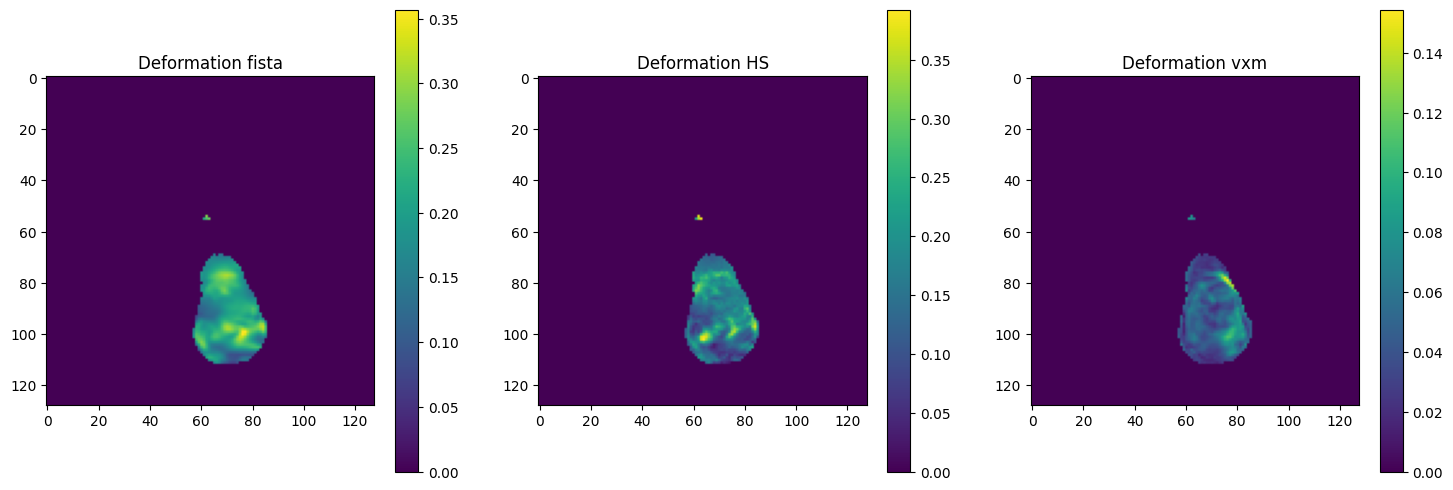

In [105]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
im0 = axes[0].imshow(def_fista[0, z_stack])
fig.colorbar(im0, ax=axes[0])
axes[0].set_title('Deformation fista')
im1 = axes[1].imshow(def_hs[0, z_stack])
fig.colorbar(im1, ax=axes[1])
axes[1].set_title('Deformation HS')
im2 = axes[2].imshow(def_vxm[0, z_stack])
fig.colorbar(im2, ax=axes[2])
axes[2].set_title('Deformation vxm')
plt.show()

In [ ]:
from optical_flow.algorithms import warp

def compute_mse_images(computed_flows_dir, images_dir, model, z_stack):
    single_computed_flow_files = list(computed_flows_dir.glob("flow_vxm*.npy"))
    
    for cf_path in single_computed_flow_files:
        cf_name = cf_path.name

        base_name = cf_name.replace('flow_vxm', '').replace('.npy', '')
        img_path = os.path.join(images_dir, base_name)
        
        img_padded, displacement, warped_source = get_img_and_results(img_path, model, default_spacing=[1.0, 0.13, 0.13])

        dis_fista = np.load(computed_flows_dir / f"flow_fista_{base_name}.npy")
        dis_hs = np.load(computed_flows_dir / f"flow_hs_{base_name}.npy")
        dis_tvl1 = np.load(computed_flows_dir / f"flow_tvl1_{base_name}.npy")
        
        warped_fista = warp(img_padded[1], dis_fista[:, 0])
        warped_hs = warp(img_padded[1], dis_hs[:, 0])       
        warped_tvl1 = warp(img_padded[1], dis_tvl1[:, 0])
        warped_vxm = warped_source.detach().numpy()[0,0]

        fig, axes = plt.subplots(1, 5, figsize=(25, 5))
        im0 = axes[0].imshow(img_padded[0, z_stack] -  img_padded[1, z_stack])
        fig.colorbar(im0, ax = axes[0])
        axes[0].set_title('Target - source')
        im1 = axes[1].imshow(img_padded[0, z_stack] -  warped_fista[z_stack])
        fig.colorbar(im1, ax = axes[1])
        axes[1].set_title('Fista warped - source')
        im2 = axes[2].imshow(img_padded[0, z_stack] -  warped_hs[z_stack])
        fig.colorbar(im2, ax = axes[2])
        axes[2].set_title('HS warped - source')
        im3 = axes[3].imshow(img_padded[0, z_stack] -  warped_tvl1[z_stack])
        fig.colorbar(im3, ax = axes[3])
        axes[3].set_title('TVL1 warped - source')
        im4 = axes[4].imshow(img_padded[0, z_stack] -  warped_vxm[z_stack])
        fig.colorbar(im4, ax = axes[4])
        axes[4].set_title('VXM warped - source')
        plt.show()

In [31]:
compute_mse_images(save_path, folder, model_aniso, 15)

TypeError: get_img_and_results() got an unexpected keyword argument 'spacing'

In [25]:
folder = Path('/Users/josephinelahmani/Desktop/nn_dis/tests/testOF')

save_path = Path('/Users/josephinelahmani/Desktop/nn_dis/tests/computed_flows')
save_path.mkdir(exist_ok=True)

save_flow_vxm(folder, model_aniso, save_path, '')

ValueError: too many values to unpack (expected 3)

In [68]:
def compute_rmse_all_methods(computed_flows_dir, gt_flow_dir):
    rmse_summary = []
    single_computed_flow_files = list(computed_flows_dir.glob("flow_vxm_*.npy"))
    
    for cf_path in single_computed_flow_files:
        cf_name = cf_path.name

        base_name = cf_name.replace('flow_vxm_', '')

        ugt_name = base_name.replace('_img.npy', '_ugt.npy')

        ugt_path = gt_flow_dir / ugt_name
        dis_gt_init = np.load(ugt_path)
        dis_gt = np.stack([reshape_img(dis_gt_init[0, 0], 32), reshape_img(dis_gt_init[1, 0], 32), reshape_img(dis_gt_init[2, 0], 32)])
        dis_fista = np.load(computed_flows_dir / f"flow_fista_{base_name}")
        dis_hs = np.load(computed_flows_dir / f"flow_hs_{base_name}")
        dis_tvl1 = np.load(computed_flows_dir / f"flow_tvl1_{base_name}")
        dis_vxm = np.load(computed_flows_dir / f"flow_vxm_{base_name}")
        
        rmse_fista = rmse(dis_fista[:,0], dis_gt)
        rmse_hs = rmse(dis_hs[:,0], dis_gt)
        rmse_tvl1 = rmse(dis_tvl1[:,0], dis_gt)
        rmse_vxm = rmse(dis_vxm[:,0], dis_gt)

        rmse_summary.append({
            "img_name": cf_name,
            "rmse_fista": float(rmse_fista),
            "rmse_hs": float(rmse_hs),
            "rmse_tvl1": float(rmse_tvl1),
            "rmse_vxm": float(rmse_vxm),
        })
    
    return rmse_summary

def compute_lame(E, nu):
    """
    Computes the Lamé parameters (μ and λ) from Young’s modulus and Poisson’s ratio.

    Args:
        E (float):
            Young’s modulus of the material.
        nu (float):
            Poisson’s ratio of the material.

    Returns:
        tuple[float, float]:
            - `mu_e` (float): Shear modulus (μ).
            - `lambda_e` (float): First Lamé parameter (λ).
    """
    lambda_e = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu))
    mu_e = E / (2.0 * (1.0 + nu))
    return mu_e, lambda_e


def compute_mec_stuff(name, computed_flows_dir, gt_flow_dir, mask, normals):

    ugt_name = name.replace('_img.npy', '_ugt.npy')

    ugt_path = gt_flow_dir / ugt_name
    
    matchE = re.search(r"E_(\d+)", name)
    if matchE is not None:
        E = float(matchE.group(1))
        
    matchnu = re.search(r"_nu_(\d+)", name)
    if matchnu is not None:
        nu = float(matchnu.group(1))
    
    mu, lambda_ = compute_lame(E, nu)
    
    displacements = {
        "gt":    np.load(ugt_path),
        "fista": np.load(computed_flows_dir / f"flow_fista_{name}"),
        "hs":    np.load(computed_flows_dir / f"flow_hs_{name}"),
        "tvl1":  np.load(computed_flows_dir / f"flow_tvl1_{name}"),
        "vxm":   np.load(computed_flows_dir / f"flow_vxm_{name}")
    }
    
    results = {}
    dis_gt_init = displacements["gt"]
    dis_gt = np.stack([reshape_img(dis_gt_init[0, 0], 32), reshape_img(dis_gt_init[1, 0], 32), reshape_img(dis_gt_init[2, 0], 32)])
    dis_gt = np.expand_dims(dis_gt, axis=1)
    strain_gt = strain_mask(dis_gt, [1, 1, 1], mask)
    def_grad_gt = deformation(strain_gt)
    stress_gt = stress_mask(strain_gt, mu, lambda_)
    traction_gt = compute_traction_3d(stress_gt[:,:,0], -normals)

    results["gt"] = {
        "displacement": dis_gt,        
        "deformation":  def_grad_gt,
        "strain":       strain_gt,
        "stress":       stress_gt,
        "normals":      normals,
        "traction":     traction_gt,
    }

    methods = ["fista", "hs", "tvl1", "vxm"]
    
    for method in methods:
        dis = displacements[method]
        
        strain = strain_mask(dis, [1, 1, 1], mask)
        def_grad = deformation(strain)
        stress = stress_mask(strain, mu, lambda_)
        traction = compute_traction_3d(stress[:,:,0], -normals)

        results[method] = {
            "displacement": dis,        
            "deformation":  def_grad,
            "strain":       strain,
            "stress":       stress,
            "normals":      normals,
            "traction":     traction,
            
            "rmse_displacement": rmse(dis, dis_gt),
            "rmse_deformation":  rmse(def_grad, def_grad_gt),
            "rmse_strain":       rmse(strain, strain_gt),
            "rmse_stress":       rmse(stress, stress_gt),
            "rmse_traction":     rmse(traction, traction_gt),
        }

    return results

In [ ]:
computed_flows_dir = Path('/Users/josephinelahmani/Desktop/nn_dis/tests/computed_flows')
gt_flow_dir = Path('/Users/josephinelahmani/helix_mount/data/synthetic/all_data')

rmse_summary = compute_rmse_all_methods(computed_flows_dir, gt_flow_dir)

methods = ['rmse_fista', 'rmse_hs', 'rmse_tvl1', 'rmse_vxm']

avg = {m: np.mean([d[m] for d in rmse_summary]) for m in methods}

for method, value in avg.items():
    print(f"{method} : {value}")

In [ ]:
img_name = 'E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy' #'E_1000.0_nu_0.4_nb_zones_9_im_01_seed_01_img.npy'
folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
img_raw = np.load(folder / f"{img_name}")
q1, q99 = np.quantile(img_raw, [0.01, 0.99])
img = np.clip((img_raw - q1) / (q99 - q1), 0, 1)

img_padded = np.stack([reshape_img(img[0], 32), reshape_img(img[1], 32)], axis=0)

mask = img_padded[0] > 0.1

mask_eroded = ndi.binary_erosion(mask)
inner_boundary_gt = mask_eroded & (~ndi.binary_erosion(mask_eroded))
normals = compute_normals_from_mask_3d(mask_eroded)
normals[:, ~inner_boundary_gt] = 0

results = compute_mec_stuff(img_name, computed_flows_dir, gt_flow_dir, normals) 

In [42]:
metrics = ["displacement", "deformation", "strain", "stress", "traction"]
methods = ["fista", "hs", "tvl1", 'vxm']

for metric in metrics:
    print(f"\n{metric}")
    for method in methods:
        val = results[method][f"rmse_{metric}"]
        print(f"{method:<8} : {val:.6e}")


displacement
fista    : 1.428353e-01
hs       : 1.563871e-01
tvl1     : 1.521091e-01
vxm      : 1.635397e-01

deformation
fista    : 5.114334e-02
hs       : 4.766799e-02
tvl1     : 4.865333e-02
vxm      : 4.872380e-02

strain
fista    : 2.076933e-02
hs       : 2.262412e-02
tvl1     : 2.357346e-02
vxm      : 2.443072e-02

stress
fista    : 2.076933e+01
hs       : 2.262412e+01
tvl1     : 2.357346e+01
vxm      : 2.443072e+01

traction
fista    : 2.124405e+01
hs       : 2.268356e+01
tvl1     : 2.322456e+01
vxm      : 2.411972e+01


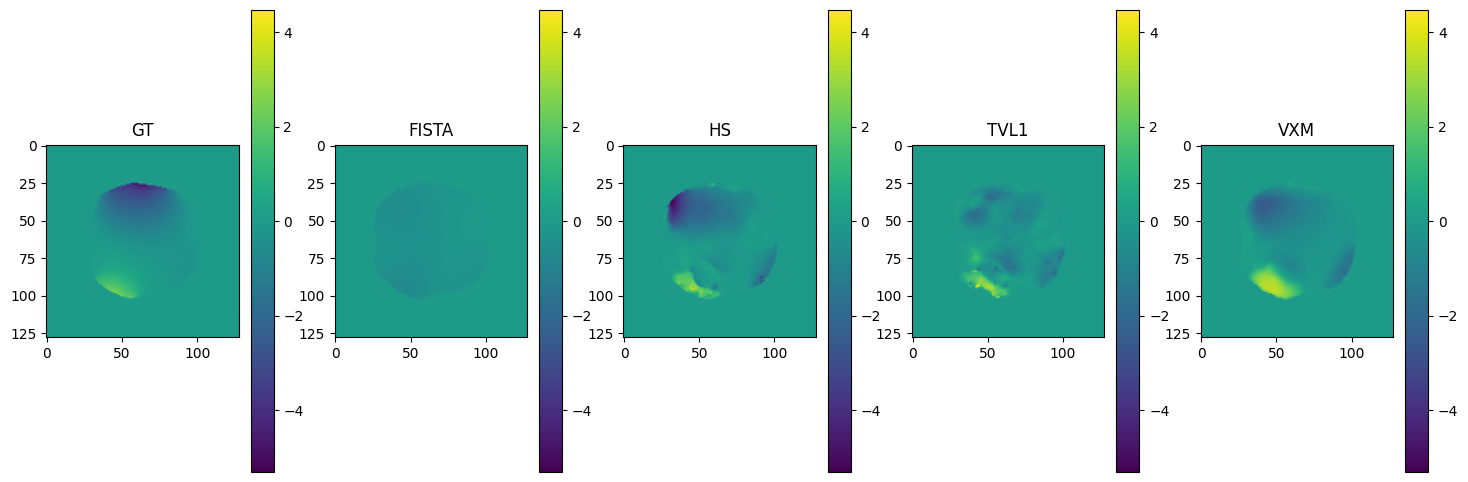

In [50]:
methods = ["gt", "fista", "hs", "tvl1", "vxm"]
method_titles = ["GT", "FISTA", "HS", "TVL1", "VXM"]
frame = 15
ax = 0

fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['displacement'][ax, 0, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['displacement'][ax, 0, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)

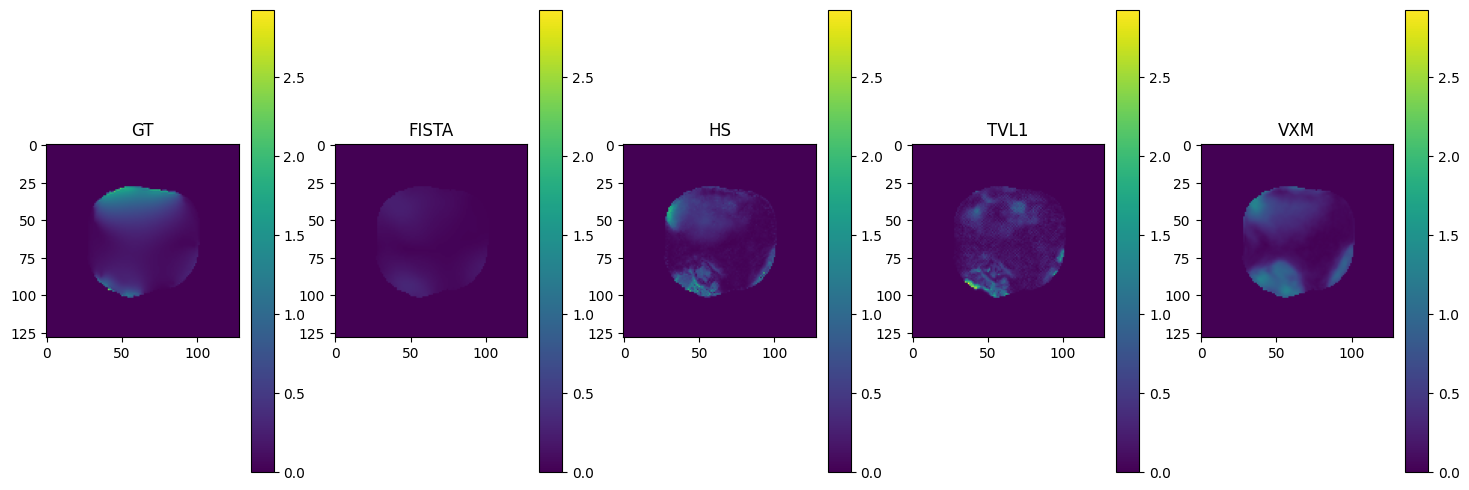

In [51]:
fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['deformation'][0, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['deformation'][0, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)

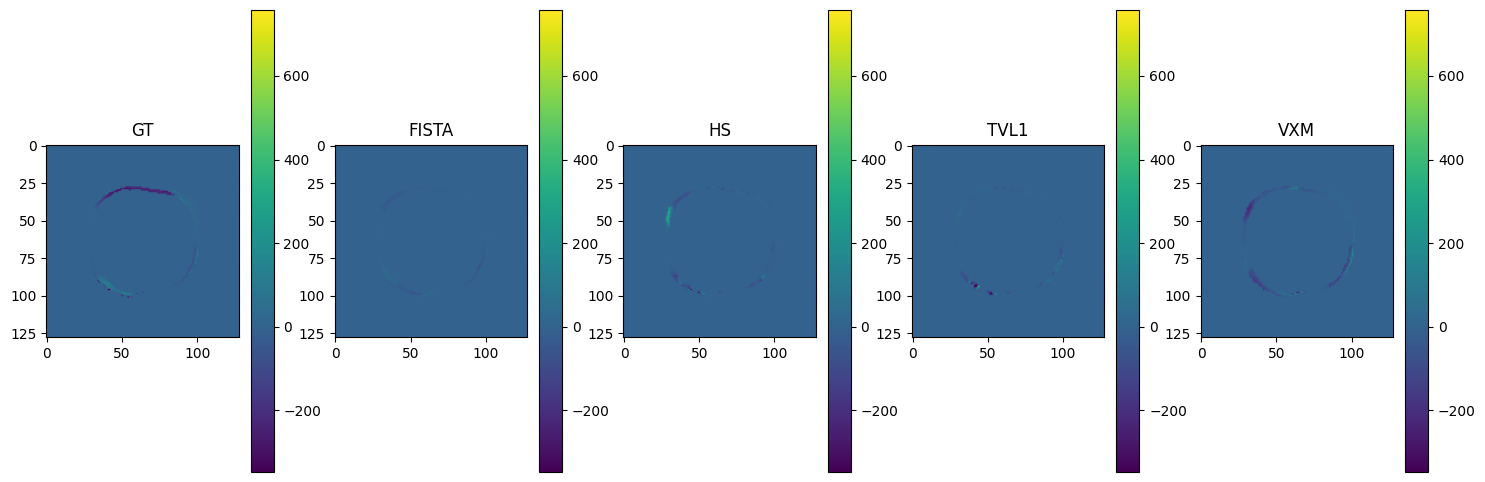

In [52]:
fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['traction'][1, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['traction'][2, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)